# Challenge 3: Can You Change the Correlation?

Prediction: the Bell-state circuit should mainly produce `00` and `11`. Adding one X gate to the second qubit should instead produce `01` and `10`.


In [6]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

SHOTS = 100


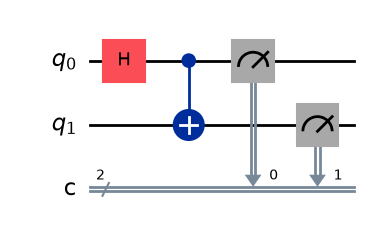

Original Bell circuit {'11': 55, '00': 45}


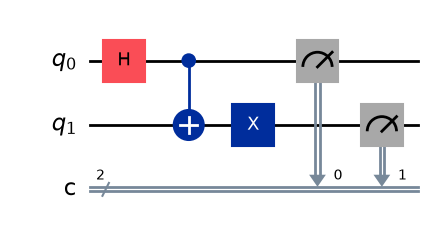

Modified circuit {'10': 53, '01': 47}


In [7]:
def run_case(modified=False):
    circuit = QuantumCircuit(2, 2)
    circuit.h(0)
    circuit.cx(0, 1)
    if modified:
        circuit.x(1)
    circuit.measure([0, 1], [0, 1])
    counts = StatevectorSampler().run([circuit], shots=SHOTS).result()[0].data.c.get_counts()
    display(circuit.draw(output="mpl"))
    print("Modified circuit" if modified else "Original Bell circuit", counts)
    return counts

original = run_case()
modified = run_case(modified=True)


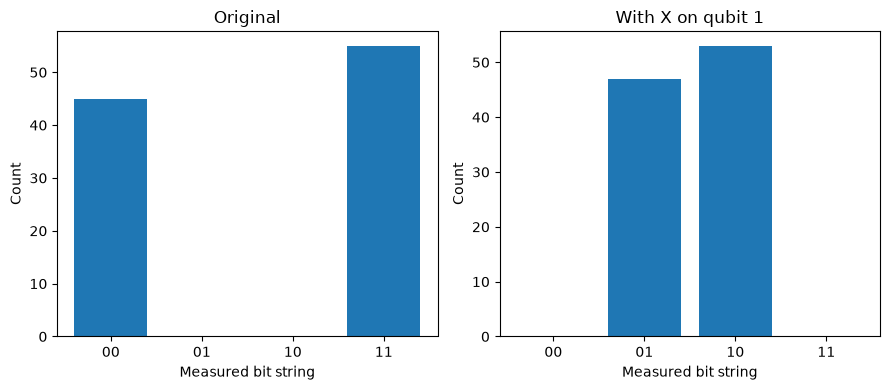

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, title, counts in zip(axes, ["Original", "With X on qubit 1"], [original, modified]):
    outcomes = ["00", "01", "10", "11"]
    ax.bar(outcomes, [counts.get(bit, 0) for bit in outcomes])
    ax.set_title(title)
    ax.set_xlabel("Measured bit string")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


## Explanation

The original circuit prepares `( |00⟩ + |11⟩ ) / √2`. The added X gate flips the second qubit and changes the state to `( |01⟩ + |10⟩ ) / √2`. The results are still linked, but the measured bits are opposite. Small count variations are expected because the circuits are sampled for only 100 shots.
